### Import Libraries

In [10]:
import numpy as np
import torch
import matplotlib.pyplot as plt

In [15]:
param = 1

In [16]:
import pandas as pd

# Path to the file in Google Drive
file_path = fr"C:\Users\Karan\Desktop\PINNS_literature_review\gray_scott_model\data\data_{param}.txt"

# Generate column names
times = range(0, 3001, 10)

columns = ["x", "y"]

for t in times:
    columns += [f"u_{t}", f"v_{t}"]

# Read the data
df = pd.read_csv(
    file_path,
    sep=r"\s+",
    comment="%",
    header=None,
    names=columns
)

# Display the DataFrame
print(df)

              x         y  u_0           v_0  u_10          v_10  u_20  \
0      0.000000  0.000000  1.0  6.044687e-78   1.0  2.204048e-58   1.0   
1      0.001818  0.000000  1.0  1.862587e-77   1.0  2.288148e-58   1.0   
2      0.000000  0.001818  1.0  1.862587e-77   1.0  2.288148e-58   1.0   
3      0.001818  0.001818  1.0  6.161572e-77   1.0  2.375532e-58   1.0   
4      0.000000  0.003970  1.0  9.483544e-77   1.0  2.614471e-58   1.0   
...         ...       ...  ...           ...   ...           ...   ...   
10196  0.993544  0.993544  1.0  6.523927e-74   1.0  5.084951e-58   1.0   
10197  0.996030  0.990724  1.0  6.075878e-74   1.0  5.649834e-58   1.0   
10198  0.993544  0.996030  1.0  1.106928e-74   1.0  3.970411e-58   1.0   
10199  0.996030  0.993544  1.0  1.106928e-74   1.0  3.970411e-58   1.0   
10200  0.996030  0.996030  1.0  1.961715e-75   1.0  3.103192e-58   1.0   

               v_20  u_30          v_30  ...    u_2960    v_2960    u_2970  \
0      3.249821e-46   1.0  2.4514

In [17]:
L = 1.0  # length of the domain
x_min, x_max = 0.0, L
y_min, y_max = 0.0, L
t_min, t_max = 0.0, 3000.0

First Metric

u: x f95=3.49  y f95=3.49  (peak x=0.50, y=0.50)
v: x f95=4.49  y f95=4.49  (peak x=0.50, y=0.50)
u: t f95=1.99  peak=0.50
v: t f95=2.99  peak=0.50


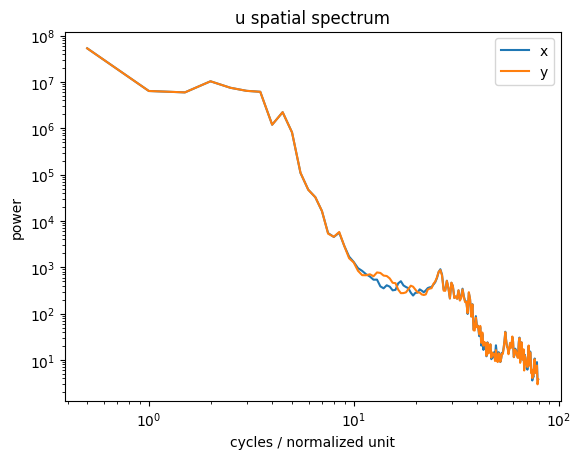

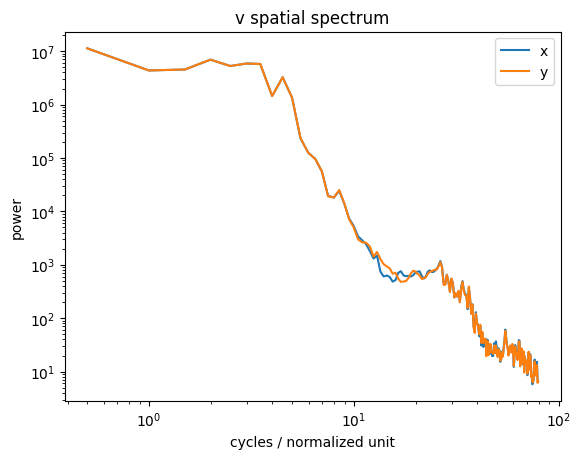

In [18]:
from scipy.spatial import Delaunay
from scipy.interpolate import LinearNDInterpolator, griddata

# ---- uniform square grid to interpolate onto ----
N = 320                                   # ~ your mesh resolution (322/335)
gx, gy = np.meshgrid(np.linspace(x_min, x_max, N),
                     np.linspace(y_min, y_max, N))
pts = df[["x", "y"]].values
tri = Delaunay(pts)                       # build triangulation once, reuse for all snapshots

def get_field(prefix, t):
    vals = df[f"{prefix}_{t}"].values
    f = LinearNDInterpolator(tri, vals)(gx, gy)
    nan = np.isnan(f)                     # points just outside the mesh hull
    if nan.any():
        f[nan] = griddata(pts, vals, (gx[nan], gy[nan]), method="nearest")
    return f                              # (N, N)

def q_freq(freqs, power, q=0.95):
    c = np.cumsum(power) / power.sum()
    return freqs[min(np.searchsorted(c, q), len(freqs) - 1)]

# ---- spatial spectrum (averaged over several developed snapshots) ----
def spatial_spectrum(prefix, t_list):
    d = 2 * (1.0 / (N - 1)) / L           # grid spacing in normalized units (domain -> length 2)
    fx = np.fft.fftshift(np.fft.fftfreq(N, d=d))
    pos = fx > 0
    win = np.outer(np.hanning(N), np.hanning(N))
    Px, Py = 0, 0
    for t in t_list:
        f = get_field(prefix, t)
        f = (f - f.mean()) * win
        P = np.abs(np.fft.fftshift(np.fft.fft2(f))) ** 2
        Px = Px + P.sum(axis=0)[pos]      # power vs x-frequency
        Py = Py + P.sum(axis=1)[pos]      # power vs y-frequency
    return fx[pos], Px, Py

for name in ["u", "v"]:
    f, Px, Py = spatial_spectrum(name, [500, 1000, 2000, 3000])
    print(f"{name}: x f95={q_freq(f,Px):.2f}  y f95={q_freq(f,Py):.2f}  "
          f"(peak x={f[np.argmax(Px)]:.2f}, y={f[np.argmax(Py)]:.2f})")

    plt.figure(); plt.loglog(f, Px, label="x"); plt.loglog(f, Py, label="y")
    plt.xlabel("cycles / normalized unit"); plt.ylabel("power"); plt.legend()
    plt.title(f"{name} spatial spectrum"); plt.savefig(f"spec_space_{name}.png")

# ---- temporal spectrum ----
def temporal_spectrum(prefix, n_pts=2000):
    cols = [f"{prefix}_{t}" for t in times]
    A = df[cols].sample(n=n_pts, random_state=0).values        # (n_pts, nt)
    A = (A - A.mean(axis=1, keepdims=True)) * np.hanning(A.shape[1])
    d = 2 * 10.0 / (t_max - t_min)
    f = np.fft.rfftfreq(A.shape[1], d=d)[1:]
    P = (np.abs(np.fft.rfft(A, axis=1)) ** 2).mean(axis=0)[1:]
    return f, P

for name in ["u", "v"]:
    f, P = temporal_spectrum(name)
    print(f"{name}: t f95={q_freq(f,P):.2f}  peak={f[np.argmax(P)]:.2f}")